# stepwise methods:

Stepwise WIS: methods text

Setup. Each test stay i has states sᵢₜ, clinician actions aᵢₜ (fluid and vasopressor), and hourly rewards rᵢₜ, where the reward is the change in health score over hour t, for t = 0, …, Tᵢ−1. We estimate the expected discounted return of the CQL policy π, V(π) = E[Σₜ γᵗ rₜ], from these logged stays, using γ = 0.975, the discount the models were trained with.

Behaviour density and per-hour ratios. A behavioural-cloning actor trained on the same data gives the density of the clinician’s action in each state, π_b(a|s). For every hour of every stay we compute the log-ratio ℓᵢₜ = log π(aᵢₜ|sᵢₜ) − log π_b(aᵢₜ|sᵢₜ). Both densities are continuous, and the log-probabilities are clipped for numerical stability. These ratios are computed once.

Cumulative weights. The weight of stay i at hour t uses only the actions taken up to and including hour t:

Lᵢₜ = Σ_{k≤t} ℓᵢₖ, wᵢₜ = exp(Lᵢₜ)

Because a reward at hour t cannot depend on later actions, later ratios are left out. Trajectory-level WIS, in contrast, weights every reward by the product over the whole stay.

Weight truncation. Cumulative products over long stays are extremely skewed. Without truncation, a single stay holds nearly all the weight (effective sample size about one stay). At each hour, among the stays still active at that hour, we therefore clip Lᵢₜ at the p-th percentile across stays before exponentiating. The percentiles (25 and 50) were fixed before any test-set evaluation. Lower percentiles mean stronger truncation. A cap of 0 gives equal weights, and the estimate reduces to the null below.

Per-hour estimate and discounting. For each hour, using only stays still active at that hour (set A_t):

vₜ = Σ_{i∈A_t} wᵢₜ rᵢₜ / Σ_{i∈A_t} wᵢₜ

and the policy value is a discounted sum over hours:

V̂ = Σₜ γᵗ vₜ

Each hour’s reward enters once, at its own hour, and the discount γᵗ is counted from the start of the stay. No discounting is applied inside vₜ, and V̂ is a sum rather than an average over hours.

Reference value. Setting all ratios to 1 gives the null estimate, V̂₀ = Σₜ γᵗ mean_{i∈A_t}(rᵢₜ), which is the clinician’s own value on the same scale. Because stays drop out as they end, V̂₀ differs slightly from the mean discounted return per stay (test: 0.678 vs 0.639). Each estimator is compared with its own null.

Uncertainty and inference. We resample stays with replacement (1,000 times), recompute both V̂ and V̂₀ on each resample, and report the percentile interval for V̂ − V̂₀. Estimates are reported separately for each of the five seeds, with RL seed x paired with the Dynamic-DeepHit seed x states. The cap sweep on the validation set is descriptive. A seed’s estimate is called uninformative when its effective sample size falls below 10% of stays (the uncapped estimate fails this in all seeds).

Limitations.

Truncation is biased, so the size of V̂ − V̂₀ depends on the cap and increases as the cap loosens. We interpret the sign and the interval relative to the null, not the magnitude.
With γ = 0.975, about 92% of the discount weight lies in the first 100 hours, so the estimate reflects agreement and outcomes in the first few days of a stay. Hours beyond that contribute almost nothing.
Importance sampling only covers regions where the clinician and policy actions overlap. Stepwise WIS is secondary to the FQE-based advantage analysis.

A small thing to check in the code: I should confirm how the reported effective sample size is aggregated across hours before you state it in the paper as a single percentage.

Trajectory-level WIS: methods text

Setup. As for stepwise WIS, each test stay i has states sᵢₜ, clinician actions aᵢₜ and hourly rewards rᵢₜ (the change in health score over hour t), t = 0, …, Tᵢ−1. The aim is to estimate the expected discounted return of the CQL policy π from these logged stays, with γ = 0.975, read from the trained models.

Value of a stay. Each stay’s logged outcome is its discounted return from the first hour, Gᵢ = Σₜ γᵗ rᵢₜ.

Importance weight. A behavioural-cloning actor gives the clinician’s action density π_b(a|s). The per-hour log-ratio is ℓᵢₜ = log π(aᵢₜ|sᵢₜ) − log π_b(aᵢₜ|sᵢₜ), with log-probabilities clipped for numerical stability. Each stay receives one weight from its entire action sequence: Lᵢ = Σₜ ℓᵢₜ, wᵢ = exp(Lᵢ).

Weight truncation. Products over a whole stay are extremely spread out, and without truncation a single stay holds nearly all the weight (test set: effective sample size 1 of 310 stays). We therefore clip the log-weights at a percentile across stays: with cap p, any Lᵢ above the p-th percentile of {L₁, …, L_N} is set to that percentile, and stays below it keep their own value. The cap is applied once, over the N whole-stay totals. We pre-specified p = 25 and 50, before test evaluation. A cap of 0 gives equal weights.

Estimator. After clipping, V̂ = Σᵢ wᵢ Gᵢ / Σᵢ wᵢ, with the weights exponentiated after subtracting the maximum log-weight for numerical stability. The effective sample size is (Σw)²/Σw², reported as a fraction of the number of stays. An estimate is called uninformative when this falls below 10%, which the uncapped estimator does in every seed.

Reference value and inference. Setting every ratio to 1 gives equal weights and the null V̂₀ = mean(Gᵢ), the clinician’s own mean discounted return. We resample stays with replacement (1,000 times), recompute V̂ and V̂₀ on each resample, and report the percentile interval for V̂ − V̂₀, separately for each seed.

Limitations. The weight depends on every action in the stay, including those at hours so late that their discount γᵗ makes their rewards negligible. Those late ratios add variance to the weight without carrying information about Gᵢ, which is dominated by roughly the first 100 hours. After capping, the estimate is therefore close to its null. This is the motivation for the stepwise estimator, which we treat as the primary WIS analysis. As for stepwise, truncation introduces bias, so the size of V̂ − V̂₀ depends on the cap and only its sign and interval relative to the null are interpreted.# 

# Is stepwise stronger or more powerful?

I’d say it is more efficient, and that is a narrower claim than “stronger”. The argument has three parts:

Same target, less noise. Both estimate the same quantity, V(π). A reward at hour k cannot depend on actions after k, so those later ratios carry no information about it. Trajectory-level includes them anyway, which only adds variance, and the variance grows with stay length (your stays reach 2 months). Stepwise drops them. Per-decision importance sampling is the standard way to do this, and in general it has lower variance than the whole-trajectory form, though that is a tendency and not a guarantee.
The discount makes it worse for trajectory-level. With γ = 0.975, Gᵢ is set by roughly the first 100 hours, while the weight is driven by all hours, so most of the weight’s variation is irrelevant to the return it multiplies.
The data show the consequence. At the same cap, the trajectory-level estimate is indistinguishable from its null, while stepwise is above its null in all seeds, with intervals that exclude zero.

Two cautions for the write-up:

Effect sizes are not comparable between the methods. Under a cap both are biased, in different ways, and each has its own null. What can be compared is the interval for V̂ − V̂₀ and the effective sample size at the same cap, not the number.
The choice has to look like it was made in advance. We moved to stepwise after trajectory-level showed nothing, and a reviewer may read it that way. The protection is to give the a priori reasons above, say that stepwise was already part of the evaluation pipeline, report both estimators for every seed and cap, and describe trajectory-level as the standard comparator that is underpowered here for the reason given. Don’t present stepwise as the method that “found” the effect.

In [1]:
import sys
import os
from pathlib import Path
import importlib
import json

import numpy as np
import matplotlib.pyplot as plt
import torch


# Optional but very useful in notebooks
%load_ext autoreload
%autoreload 2

repo_root = Path("/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl")
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from src.rl.analysis import runs as R, models as M, data as D
import src.rl.evaluate_wis as wis

R.set_path_mappings([("/rds/general/user/jormond/home/projects/ai_clinician",
                      "/home/jake/Documents/AI_Clinician/models")])

[('/rds/general/user/jormond/home/projects/ai_clinician',
  '/home/jake/Documents/AI_Clinician/models')]

In [2]:
ALPHA = 0.029
rl_root = "/home/jake/Documents/AI_Clinician/models/rl_models/choc"

cql_dir = os.path.join(rl_root, "cql_with_logprobs", "split_0", "sepsis", "intake-vis",
                       "picu_patients_health_score_from_picu_dataset", "with_actions",
                       "health_score_change_only", "alpha_sweep")
bc_dir = os.path.join(rl_root, "bc_with_logprobs", "split_0", "sepsis", "intake-vis",
                      "picu_patients", "with_actions")

for name, d in (("cql_dir", cql_dir), ("bc_dir", bc_dir)):
    print(f"{name}: {d}")

is_alpha = lambda r: np.isclose(float(r.get("cql_alpha")), ALPHA)
cql_study = R.make_study(cql_dir, family="cql", group_by=(), include=is_alpha, name="cql")
bc_study = R.make_study(bc_dir, family="bc", group_by=(), name="bc")

cql_models = M.load_study_models(cql_study)[()]
bc_models = M.load_study_models(bc_study)[()]
assert sorted(cql_models) == sorted(bc_models) == [0, 1, 2, 3, 4]

# every CQL seed must be paired with the BC seed that shares its state embedding
for s in sorted(cql_models):
    print(s, cql_models[s].record.data_identity.short(), "|", bc_models[s].record.data_identity.short())

store = D.DataStore(keep=("val", "test"))

cql_dir: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/alpha_sweep
bc_dir: /home/jake/Documents/AI_Clinician/models/rl_models/choc/bc_with_logprobs/split_0/sepsis/intake-vis/picu_patients/with_actions
  overrides applied under /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/alpha_sweep:
    vaso_reward_coefficient: saved=0.1 -> used=0.0  [rule vaso_reward_gate: add_reward_to_vaso_dosing is False]  seeds=[0, 1, 2, 3, 4]
  loaded LoadedModel(cql seed 0: actor, critic)
  loaded LoadedModel(cql seed 1: actor, critic)
  loaded LoadedModel(cql seed 2: actor, critic)
  loaded LoadedModel(cql seed 3: actor, critic)
  loaded LoadedModel(cql seed 4: actor, critic)
  loaded LoadedModel(bc seed 0: actor)
  loaded LoadedModel(bc se

In [3]:
results = wis.run_wis_for_models(cql_models, bc_models, store, split="val", gamma=0.975,
                                 weight_cap_percentile=None, include_myopic=False)

  building processors for state seed 0, shared reward [choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7]  (splits: test, val)
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type

=== Seed 0 ===
  [std_source=bc]
  Clinician baseline (logged) return: 0.8827 +/- 0.4020 (SEM)
  Trajectory-level WIS: -0.8227  [-0.8227, 5.9534]  ESS=1.0/240 (0.4%)
  Stepwise WIS:         3.7752  [1.1765, 18.2727]
  Minus null (policy = clinician): trajectory -1.705 [-2.503, +5.424]   stepwise +2.865 [+0.458, +16.999]  (nulls 0.883 / 0.910)
  Top-1% of trajectories hold 100.0% of total weight (max single trajectory: 100.0%)
  building processors for state seed 1, shared reward [choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7]  (sp

In [4]:
import pandas as pd

def wis_table(results):
    rows = []
    for r in results:
        t, s, ci, dg = r["trajectory_wis"], r["stepwise_wis"], r["bootstrap_ci"], r["weight_diagnostics"]
        rows.append({"seed": r["seed"], "baseline": r["baseline_mean"],
                     "traj": t["value"], "traj_lo": ci["trajectory"]["ci_lower"], "traj_hi": ci["trajectory"]["ci_upper"],
                     "step": s["value"], "step_lo": ci["stepwise"]["ci_lower"], "step_hi": ci["stepwise"]["ci_upper"],
                     "ess_frac": dg["ess_frac"]})
    return pd.DataFrame(rows).round(3)

res_by_cap = {}
for cap in (25, 50):
    print(f"\n######## weight_cap_percentile = {cap}")
    res_by_cap[cap] = wis.run_wis_for_models(cql_models, bc_models, store, split="val", gamma=0.975,
                                             weight_cap_percentile=cap, include_myopic=False)
    display(wis_table(res_by_cap[cap]))
display(wis_table(results))      # the uncapped result, for the same layout


######## weight_cap_percentile = 25

=== Seed 0 ===
  [std_source=bc]
  Clinician baseline (logged) return: 0.8827 +/- 0.4020 (SEM)
  Trajectory-level WIS: 1.1570  [0.2180, 2.0321]  ESS=180.0/240 (75.0%)
  Stepwise WIS:         1.6457  [0.7488, 2.5255]
  Minus null (policy = clinician): trajectory +0.274 [-0.241, +0.716]   stepwise +0.735 [+0.333, +1.108]  (nulls 0.883 / 0.910)
  Top-1% of trajectories hold 1.7% of total weight (max single trajectory: 0.6%)

=== Seed 1 ===
  [std_source=bc]
  Clinician baseline (logged) return: 0.8827 +/- 0.4020 (SEM)
  Trajectory-level WIS: 1.0387  [0.1958, 1.9740]  ESS=180.0/240 (75.0%)
  Stepwise WIS:         1.4233  [0.5388, 2.3634]
  Minus null (policy = clinician): trajectory +0.156 [-0.233, +0.653]   stepwise +0.513 [+0.135, +0.928]  (nulls 0.883 / 0.910)
  Top-1% of trajectories hold 1.7% of total weight (max single trajectory: 0.6%)

=== Seed 2 ===
  [std_source=bc]
  Clinician baseline (logged) return: 0.8827 +/- 0.4020 (SEM)
  Trajectory-le

,seed,baseline,traj,traj_lo,traj_hi,step,step_lo,step_hi,ess_frac
0,0,0.883,1.157,0.218,2.032,1.646,0.749,2.525,0.75
1,1,0.883,1.039,0.196,1.974,1.423,0.539,2.363,0.75
2,2,0.883,1.248,0.337,2.101,1.638,0.772,2.472,0.75
3,3,0.883,0.923,0.140,1.966,1.480,0.583,2.441,0.75
4,4,0.883,1.194,0.314,2.092,1.728,0.842,2.607,0.75



######## weight_cap_percentile = 50

=== Seed 0 ===
  [std_source=bc]
  Clinician baseline (logged) return: 0.8827 +/- 0.4020 (SEM)
  Trajectory-level WIS: 0.8961  [-0.2778, 1.8981]  ESS=120.0/240 (50.0%)
  Stepwise WIS:         2.1425  [1.0565, 3.2538]
  Minus null (policy = clinician): trajectory +0.013 [-0.772, +0.742]   stepwise +1.232 [+0.543, +1.926]  (nulls 0.883 / 0.910)
  Top-1% of trajectories hold 2.5% of total weight (max single trajectory: 0.8%)

=== Seed 1 ===
  [std_source=bc]
  Clinician baseline (logged) return: 0.8827 +/- 0.4020 (SEM)
  Trajectory-level WIS: 0.6880  [-0.4318, 1.7807]  ESS=120.0/240 (50.0%)
  Stepwise WIS:         1.8153  [0.8534, 2.9296]
  Minus null (policy = clinician): trajectory -0.195 [-0.948, +0.597]   stepwise +0.905 [+0.315, +1.638]  (nulls 0.883 / 0.910)
  Top-1% of trajectories hold 2.5% of total weight (max single trajectory: 0.8%)

=== Seed 2 ===
  [std_source=bc]
  Clinician baseline (logged) return: 0.8827 +/- 0.4020 (SEM)
  Trajectory-

,seed,baseline,traj,traj_lo,traj_hi,step,step_lo,step_hi,ess_frac
0,0,0.883,0.896,-0.278,1.898,2.142,1.056,3.254,0.5
1,1,0.883,0.688,-0.432,1.781,1.815,0.853,2.930,0.5
2,2,0.883,1.285,0.037,2.466,2.047,0.958,3.059,0.5
3,3,0.883,0.812,-0.268,1.908,2.287,1.125,3.508,0.5
4,4,0.883,0.934,-0.279,1.928,2.166,1.174,3.220,0.5


,seed,baseline,traj,traj_lo,traj_hi,step,step_lo,step_hi,ess_frac
0,0,0.883,-0.823,-0.823,5.953,3.775,1.176,18.273,0.004
1,1,0.883,0.789,-4.444,1.489,4.063,-2.759,9.576,0.004
2,2,0.883,2.948,-0.740,9.757,4.154,0.760,6.984,0.004
3,3,0.883,-4.440,-4.444,2.999,3.063,1.393,29.918,0.004
4,4,0.883,-4.444,-4.444,11.576,4.330,-2.618,11.594,0.004


In [5]:
# Cell 2 addition
wis_dir = "/home/jake/Documents/AI_Clinician/models/analysis/wis_final_models"
sig = wis.models_signature(cql_models, bc_models)

def run_cached(cap, split="val"):
    name = "uncapped" if cap is None else f"cap{cap}"
    meta = dict(split=split, cap=cap, gamma=wis.discount_from_models(cql_models), n_bootstrap=1000, models=sig)
    return wis.cached_results(
        os.path.join(wis_dir, f"wis_{split}_{name}.pkl"),
        lambda: wis.run_wis_for_models(cql_models, bc_models, store, split=split,
                                       weight_cap_percentile=cap, include_myopic=False, cache_dir=wis_dir),
        meta)

gamma = 0.975 (CQL models' saved discount)
CQL seeds loaded: [0]
BC seeds loaded:  [0]
Matched 1 (CQL, BC) pairs by results.json seed: [0]

=== Seed 0: building trajectories once, then sweeping 9 cap levels ===
  wcap=  1.0  traj=0.981 (traj ESS 98.8%)  step=0.964 (step ESS 98.8%)
  wcap=  5.0  traj=1.135 (traj ESS 95.0%)  step=1.102 (step ESS 95.0%)
  wcap= 10.0  traj=1.002 (traj ESS 90.0%)  step=1.253 (step ESS 90.2%)
  wcap= 25.0  traj=1.157 (traj ESS 75.0%)  step=1.646 (step ESS 75.5%)
  wcap= 50.0  traj=0.896 (traj ESS 50.0%)  step=2.142 (step ESS 51.4%)
  wcap= 75.0  traj=0.592 (traj ESS 25.0%)  step=3.408 (step ESS 26.5%)
  wcap= 90.0  traj=1.838 (traj ESS 10.3%)  step=3.658 (step ESS 11.7%)
  wcap= 95.0  traj=0.488 (traj ESS 5.7%)  step=4.488 (step ESS 6.5%)
  wcap= 99.0  traj=2.549 (traj ESS 1.3%)  step=7.962 (step ESS 1.7%)
CQL seeds loaded: [1]
BC seeds loaded:  [1]
Matched 1 (CQL, BC) pairs by results.json seed: [1]

=== Seed 1: building trajectories once, then sweeping 9 c

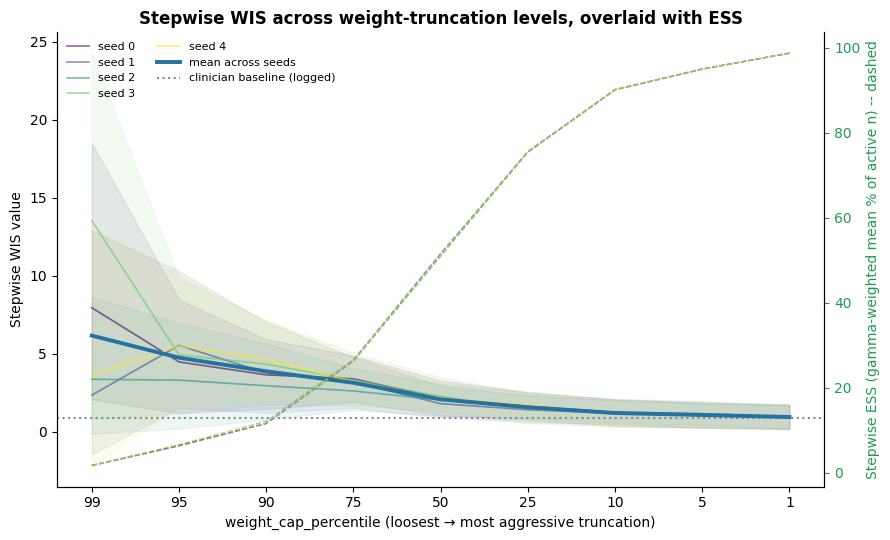

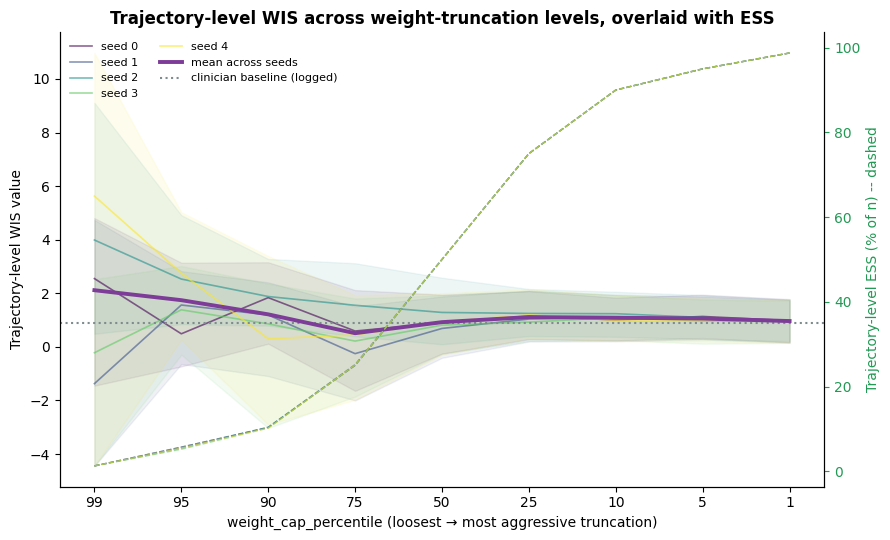

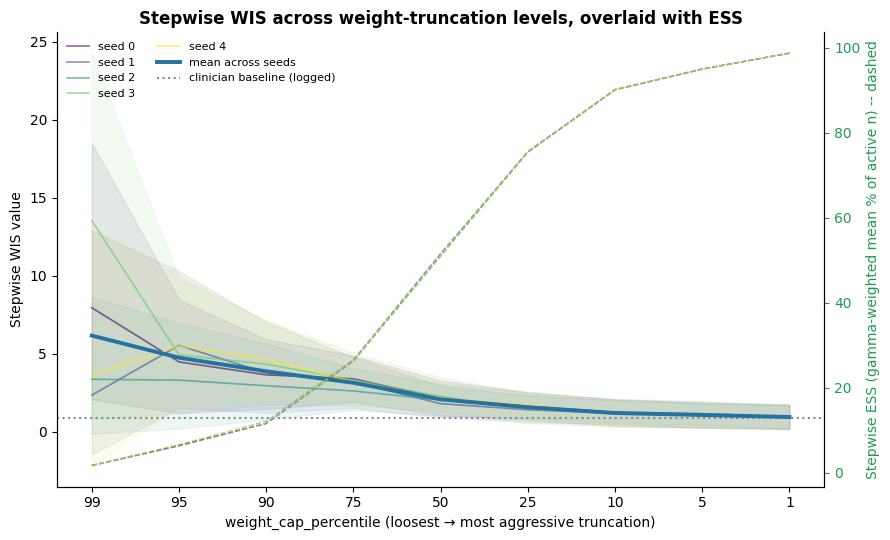

In [6]:
caps = [1, 5, 10, 25, 50, 75, 90, 95, 99]
sweep = wis.run_weight_truncation_sweep_for_models(cql_models, bc_models, store, caps, split="val", n_bootstrap=300)
wis.plot_weight_truncation_sweep(sweep, estimator="trajectory")
wis.plot_weight_truncation_sweep(sweep, estimator="stepwise")

In [7]:
caps = [1, 5, 10, 25, 50, 75, 90, 95, 99]
meta = dict(split="val", caps=caps, gamma=wis.discount_from_models(cql_models), n_bootstrap=300, models=sig)
sweep = wis.cached_results(
    os.path.join(wis_dir, "wis_val_sweep.pkl"),
    lambda: wis.run_weight_truncation_sweep_for_models(cql_models, bc_models, store, caps, split="val",
                                                       n_bootstrap=300, cache_dir=wis_dir),
    meta)

gamma = 0.975 (CQL models' saved discount)
CQL seeds loaded: [0]
BC seeds loaded:  [0]
Matched 1 (CQL, BC) pairs by results.json seed: [0]

=== Seed 0: building trajectories once, then sweeping 9 cap levels ===
  wcap=  1.0  traj=0.981 (traj ESS 98.8%)  step=0.964 (step ESS 98.8%)
  wcap=  5.0  traj=1.135 (traj ESS 95.0%)  step=1.102 (step ESS 95.0%)
  wcap= 10.0  traj=1.002 (traj ESS 90.0%)  step=1.253 (step ESS 90.2%)
  wcap= 25.0  traj=1.157 (traj ESS 75.0%)  step=1.646 (step ESS 75.5%)
  wcap= 50.0  traj=0.896 (traj ESS 50.0%)  step=2.142 (step ESS 51.4%)
  wcap= 75.0  traj=0.592 (traj ESS 25.0%)  step=3.408 (step ESS 26.5%)
  wcap= 90.0  traj=1.838 (traj ESS 10.3%)  step=3.658 (step ESS 11.7%)
  wcap= 95.0  traj=0.488 (traj ESS 5.7%)  step=4.488 (step ESS 6.5%)
  wcap= 99.0  traj=2.549 (traj ESS 1.3%)  step=7.962 (step ESS 1.7%)
CQL seeds loaded: [1]
BC seeds loaded:  [1]
Matched 1 (CQL, BC) pairs by results.json seed: [1]

=== Seed 1: building trajectories once, then sweeping 9 c

In [8]:
for r in results:
    null_traj = [dict(t, log_ratio=np.zeros_like(t["log_ratio"])) for t in r["trajectories"]]
    print(r["seed"], "stepwise null:", round(wis.compute_stepwise_wis(null_traj, 0.975)["value"], 3),
          "| trajectory null (= baseline):", round(wis.compute_trajectory_wis(null_traj, 0.975)["value"], 3))

0 stepwise null: 0.91 | trajectory null (= baseline): 0.883
1 stepwise null: 0.91 | trajectory null (= baseline): 0.883
2 stepwise null: 0.91 | trajectory null (= baseline): 0.883
3 stepwise null: 0.91 | trajectory null (= baseline): 0.883
4 stepwise null: 0.91 | trajectory null (= baseline): 0.883


In [9]:
def diff_table(results):
    rows = []
    for r in results:
        m = r["minus_null"]
        rows.append({"seed": r["seed"], "ess_frac": r["weight_diagnostics"]["ess_frac"],
                     "traj_diff": m["trajectory"]["diff"], "traj_lo": m["trajectory"]["ci_lower"], "traj_hi": m["trajectory"]["ci_upper"],
                     "step_diff": m["stepwise"]["diff"], "step_lo": m["stepwise"]["ci_lower"], "step_hi": m["stepwise"]["ci_upper"]})
    return pd.DataFrame(rows).round(3)

for cap in (25, 50):
    res = wis.run_wis_for_models(cql_models, bc_models, store, split="val", gamma=0.975,
                                 weight_cap_percentile=cap, include_myopic=False)
    print(f"\ncap {cap}"); display(diff_table(res))


=== Seed 0 ===
  [std_source=bc]
  Clinician baseline (logged) return: 0.8827 +/- 0.4020 (SEM)
  Trajectory-level WIS: 1.1570  [0.2180, 2.0321]  ESS=180.0/240 (75.0%)
  Stepwise WIS:         1.6457  [0.7488, 2.5255]
  Minus null (policy = clinician): trajectory +0.274 [-0.241, +0.716]   stepwise +0.735 [+0.333, +1.108]  (nulls 0.883 / 0.910)
  Top-1% of trajectories hold 1.7% of total weight (max single trajectory: 0.6%)

=== Seed 1 ===
  [std_source=bc]
  Clinician baseline (logged) return: 0.8827 +/- 0.4020 (SEM)
  Trajectory-level WIS: 1.0387  [0.1958, 1.9740]  ESS=180.0/240 (75.0%)
  Stepwise WIS:         1.4233  [0.5388, 2.3634]
  Minus null (policy = clinician): trajectory +0.156 [-0.233, +0.653]   stepwise +0.513 [+0.135, +0.928]  (nulls 0.883 / 0.910)
  Top-1% of trajectories hold 1.7% of total weight (max single trajectory: 0.6%)

=== Seed 2 ===
  [std_source=bc]
  Clinician baseline (logged) return: 0.8827 +/- 0.4020 (SEM)
  Trajectory-level WIS: 1.2478  [0.3365, 2.1010]  ES

,seed,ess_frac,traj_diff,traj_lo,traj_hi,step_diff,step_lo,step_hi
0,0,0.75,0.274,-0.241,0.716,0.735,0.333,1.108
1,1,0.75,0.156,-0.233,0.653,0.513,0.135,0.928
2,2,0.75,0.365,-0.210,0.773,0.727,0.321,1.124
3,3,0.75,0.041,-0.369,0.728,0.570,0.277,0.915
4,4,0.75,0.311,-0.188,0.789,0.818,0.433,1.211



=== Seed 0 ===
  [std_source=bc]
  Clinician baseline (logged) return: 0.8827 +/- 0.4020 (SEM)
  Trajectory-level WIS: 0.8961  [-0.2778, 1.8981]  ESS=120.0/240 (50.0%)
  Stepwise WIS:         2.1425  [1.0565, 3.2538]
  Minus null (policy = clinician): trajectory +0.013 [-0.772, +0.742]   stepwise +1.232 [+0.543, +1.926]  (nulls 0.883 / 0.910)
  Top-1% of trajectories hold 2.5% of total weight (max single trajectory: 0.8%)

=== Seed 1 ===
  [std_source=bc]
  Clinician baseline (logged) return: 0.8827 +/- 0.4020 (SEM)
  Trajectory-level WIS: 0.6880  [-0.4318, 1.7807]  ESS=120.0/240 (50.0%)
  Stepwise WIS:         1.8153  [0.8534, 2.9296]
  Minus null (policy = clinician): trajectory -0.195 [-0.948, +0.597]   stepwise +0.905 [+0.315, +1.638]  (nulls 0.883 / 0.910)
  Top-1% of trajectories hold 2.5% of total weight (max single trajectory: 0.8%)

=== Seed 2 ===
  [std_source=bc]
  Clinician baseline (logged) return: 0.8827 +/- 0.4020 (SEM)
  Trajectory-level WIS: 1.2850  [0.0366, 2.4659]  

,seed,ess_frac,traj_diff,traj_lo,traj_hi,step_diff,step_lo,step_hi
0,0,0.5,0.013,-0.772,0.742,1.232,0.543,1.926
1,1,0.5,-0.195,-0.948,0.597,0.905,0.315,1.638
2,2,0.5,0.402,-0.405,1.172,1.137,0.503,1.827
3,3,0.5,-0.071,-0.808,0.707,1.377,0.754,2.128
4,4,0.5,0.051,-0.822,0.717,1.256,0.585,2.036


# Test set

“On the held-out test set (310 stays), uncapped WIS had an effective sample size of about one stay and was uninformative. With weights truncated at the 25th and 50th percentiles, stepwise WIS exceeded its null (the clinician’s own policy) in all five seeds, with bootstrap intervals above zero (differences +0.33 to +0.64 and +0.58 to +0.81 in discounted health-score units). Trajectory-level WIS was statistically indistinguishable from the clinician. The stepwise differences increased with the truncation level, so we interpret them as consistent in direction and not as an estimate of the size of the improvement.”

In [10]:
# Test set, run once: uncapped
results_test = run_cached(None, split="test")
display(wis_table(results_test))

gamma = 0.975 (CQL models' saved discount)

=== Seed 0 ===
  [std_source=bc]
  Clinician baseline (logged) return: 0.6391 +/- 0.3344 (SEM)
  Trajectory-level WIS: -2.6721  [-18.3670, 4.3475]  ESS=1.0/310 (0.3%)
  Stepwise WIS:         1.3172  [-2.5754, 3.9083]
  Minus null (policy = clinician): trajectory -3.311 [-18.874, +3.807]   stepwise +0.639 [-3.250, +3.087]  (nulls 0.639 / 0.678)
  Top-1% of trajectories hold 100.0% of total weight (max single trajectory: 100.0%)

=== Seed 1 ===
  [std_source=bc]
  Clinician baseline (logged) return: 0.6391 +/- 0.3344 (SEM)
  Trajectory-level WIS: -7.4566  [-7.4566, 4.1356]  ESS=1.0/310 (0.3%)
  Stepwise WIS:         3.1296  [0.9597, 15.1532]
  Minus null (policy = clinician): trajectory -8.096 [-8.613, +3.356]   stepwise +2.451 [+0.158, +14.452]  (nulls 0.639 / 0.678)
  Top-1% of trajectories hold 100.0% of total weight (max single trajectory: 100.0%)

=== Seed 2 ===
  [std_source=bc]
  Clinician baseline (logged) return: 0.6391 +/- 0.3344 (SEM

,seed,baseline,traj,traj_lo,traj_hi,step,step_lo,step_hi,ess_frac
0,0,0.639,-2.672,-18.367,4.348,1.317,-2.575,3.908,0.003
1,1,0.639,-7.457,-7.457,4.136,3.130,0.960,15.153,0.003
2,2,0.639,-3.285,-4.908,2.656,-2.767,-5.395,-0.310,0.004
3,3,0.639,-2.672,-2.672,5.247,0.053,-0.975,3.332,0.003
4,4,0.639,-0.740,-4.908,2.136,1.515,-1.509,10.753,0.003


In [11]:
# Test set: the two pre-fixed caps
res_by_cap_test = {}
for cap in (25, 50):
    print(f"\n######## TEST, weight_cap_percentile = {cap}")
    res_by_cap_test[cap] = run_cached(cap, split="test")
    display(wis_table(res_by_cap_test[cap]))
    display(diff_table(res_by_cap_test[cap]))


######## TEST, weight_cap_percentile = 25
gamma = 0.975 (CQL models' saved discount)

=== Seed 0 ===
  log-probs loaded from /home/jake/Documents/AI_Clinician/models/analysis/wis_final_models/wis_logprobs_test_seed0.npz
  [std_source=bc]
  Clinician baseline (logged) return: 0.6391 +/- 0.3344 (SEM)
  Trajectory-level WIS: 0.8736  [0.1397, 1.6899]  ESS=232.0/310 (74.8%)
  Stepwise WIS:         1.3151  [0.5322, 2.0391]
  Minus null (policy = clinician): trajectory +0.235 [-0.093, +0.708]   stepwise +0.637 [+0.300, +0.971]  (nulls 0.639 / 0.678)
  Top-1% of trajectories hold 1.7% of total weight (max single trajectory: 0.4%)

=== Seed 1 ===
  log-probs loaded from /home/jake/Documents/AI_Clinician/models/analysis/wis_final_models/wis_logprobs_test_seed1.npz
  [std_source=bc]
  Clinician baseline (logged) return: 0.6391 +/- 0.3344 (SEM)
  Trajectory-level WIS: 0.7580  [0.0131, 1.5902]  ESS=232.1/310 (74.9%)
  Stepwise WIS:         1.0068  [0.1794, 1.8049]
  Minus null (policy = clinician)

,seed,baseline,traj,traj_lo,traj_hi,step,step_lo,step_hi,ess_frac
0,0,0.639,0.874,0.140,1.690,1.315,0.532,2.039,0.748
1,1,0.639,0.758,0.013,1.590,1.007,0.179,1.805,0.749
2,2,0.639,0.796,0.036,1.537,1.140,0.359,1.862,0.751
3,3,0.639,0.848,0.143,1.638,1.289,0.421,2.133,0.748
4,4,0.639,0.826,-0.011,1.581,1.029,0.233,1.798,0.749


,seed,ess_frac,traj_diff,traj_lo,traj_hi,step_diff,step_lo,step_hi
0,0,0.748,0.235,-0.093,0.708,0.637,0.300,0.971
1,1,0.749,0.119,-0.193,0.515,0.329,0.029,0.625
2,2,0.751,0.157,-0.258,0.538,0.462,0.124,0.773
3,3,0.748,0.209,-0.127,0.592,0.611,0.321,0.929
4,4,0.749,0.187,-0.183,0.527,0.351,0.036,0.653



######## TEST, weight_cap_percentile = 50
gamma = 0.975 (CQL models' saved discount)

=== Seed 0 ===
  log-probs loaded from /home/jake/Documents/AI_Clinician/models/analysis/wis_final_models/wis_logprobs_test_seed0.npz
  [std_source=bc]
  Clinician baseline (logged) return: 0.6391 +/- 0.3344 (SEM)
  Trajectory-level WIS: 0.8350  [-0.2362, 1.8831]  ESS=155.1/310 (50.0%)
  Stepwise WIS:         1.2825  [0.2571, 2.2052]
  Minus null (policy = clinician): trajectory +0.196 [-0.423, +0.860]   stepwise +0.604 [+0.020, +1.227]  (nulls 0.639 / 0.678)
  Top-1% of trajectories hold 2.6% of total weight (max single trajectory: 0.6%)

=== Seed 1 ===
  log-probs loaded from /home/jake/Documents/AI_Clinician/models/analysis/wis_final_models/wis_logprobs_test_seed1.npz
  [std_source=bc]
  Clinician baseline (logged) return: 0.6391 +/- 0.3344 (SEM)
  Trajectory-level WIS: 0.8837  [-0.1417, 1.9030]  ESS=155.0/310 (50.0%)
  Stepwise WIS:         1.4451  [0.4034, 2.4093]
  Minus null (policy = clinicia

,seed,baseline,traj,traj_lo,traj_hi,step,step_lo,step_hi,ess_frac
0,0,0.639,0.835,-0.236,1.883,1.282,0.257,2.205,0.5
1,1,0.639,0.884,-0.142,1.903,1.445,0.403,2.409,0.5
2,2,0.639,0.355,-0.498,1.430,1.373,0.475,2.307,0.5
3,3,0.639,0.658,-0.387,1.626,1.488,0.517,2.488,0.5
4,4,0.639,0.607,-0.324,1.743,1.262,0.354,2.247,0.5


,seed,ess_frac,traj_diff,traj_lo,traj_hi,step_diff,step_lo,step_hi
0,0,0.5,0.196,-0.423,0.860,0.604,0.020,1.227
1,1,0.5,0.245,-0.420,0.891,0.767,0.150,1.313
2,2,0.5,-0.284,-0.825,0.464,0.695,0.091,1.299
3,3,0.5,0.019,-0.679,0.669,0.810,0.246,1.380
4,4,0.5,-0.033,-0.582,0.747,0.584,0.035,1.177


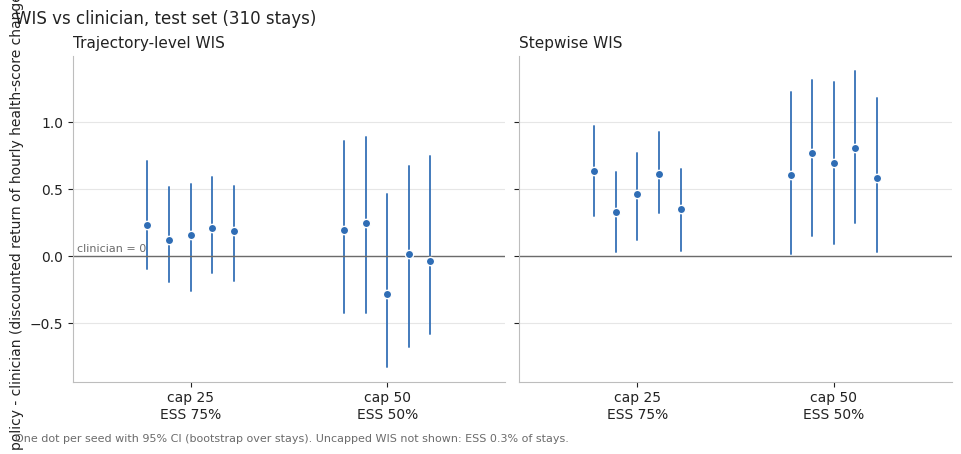

In [12]:
wis.plot_wis_summary(res_by_cap_test, title="WIS vs clinician, test set (310 stays)",
                     uncapped=results_test, save_path=os.path.join(wis_dir, "wis_test_summary.png"));

In [13]:
caps = [1, 5, 10, 25, 50, 75, 90, 95, 99]
sweep = wis.run_weight_truncation_sweep_for_models(cql_models, bc_models, store, caps, split="test", n_bootstrap=300)

gamma = 0.975 (CQL models' saved discount)
CQL seeds loaded: [0]
BC seeds loaded:  [0]
Matched 1 (CQL, BC) pairs by results.json seed: [0]

=== Seed 0: building trajectories once, then sweeping 9 cap levels ===
  wcap=  1.0  traj=0.589 (traj ESS 98.7%)  step=0.725 (step ESS 98.9%)
  wcap=  5.0  traj=0.712 (traj ESS 94.8%)  step=0.791 (step ESS 94.9%)
  wcap= 10.0  traj=0.738 (traj ESS 90.0%)  step=0.948 (step ESS 90.2%)
  wcap= 25.0  traj=0.874 (traj ESS 74.8%)  step=1.315 (step ESS 75.6%)
  wcap= 50.0  traj=0.835 (traj ESS 50.0%)  step=1.282 (step ESS 51.3%)
  wcap= 75.0  traj=0.472 (traj ESS 25.2%)  step=1.150 (step ESS 26.5%)
  wcap= 90.0  traj=-0.317 (traj ESS 10.3%)  step=0.860 (step ESS 11.7%)
  wcap= 95.0  traj=-1.685 (traj ESS 6.1%)  step=1.310 (step ESS 6.6%)
  wcap= 99.0  traj=-5.802 (traj ESS 1.4%)  step=0.438 (step ESS 1.7%)
CQL seeds loaded: [1]
BC seeds loaded:  [1]
Matched 1 (CQL, BC) pairs by results.json seed: [1]

=== Seed 1: building trajectories once, then sweeping 

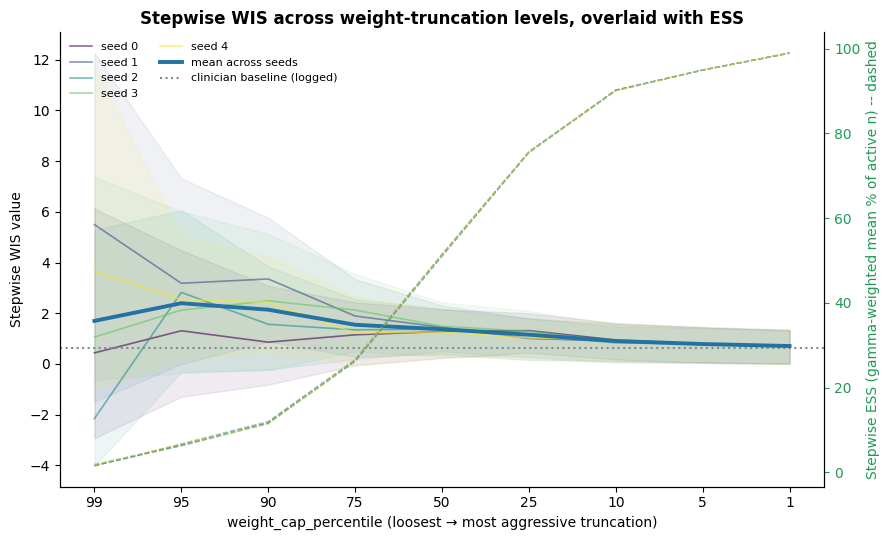

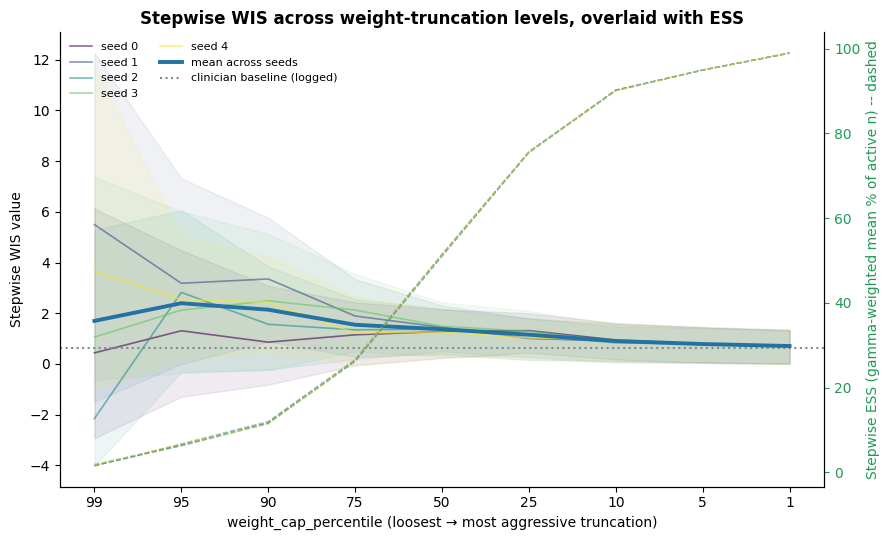

In [14]:
wis.plot_weight_truncation_sweep(sweep, estimator="stepwise")